In [482]:
import pypsa 
import pandas as pd

In [483]:
ship_profiles = pd.read_csv("Data/ship_profiles/ship_sea.csv")

dme_load_profile = ship_profiles["dme_load_morocco"]
dme_deload_profile = ship_profiles["dme_deload_rotterdam"]

co2_load_profile = ship_profiles["co2_load_rotterdam"]
co2_deload_profile = ship_profiles["co2_deload_morocco"]

ship_profile = ship_profiles["at_sea"] * 12

dme_source = ship_profiles["import_dme"]
co2_source = ship_profiles["import_co2"]


In [ ]:
# Kleines vereinfachtes Test modell zur Validierung des Schifftransport

ship_profiles = pd.read_csv("Data/ship_profiles/ship_sea.csv")

n = pypsa.Network()
n.set_snapshots(ship_profiles.index)

# Marocco components simplified
n.add("Bus", "morocco_hydrogen_bus") # MWh 
n.add("Generator", "hydrogen_source", bus="morocco_hydrogen_bus", p_nom=10000, marginal_cost=154) # in MWh


n.add("Bus", "morocco_dme_bus") # MWh
n.add("Link", "morocco_dme_loading_link", bus0="morocco_dme_bus", bus1="ship_dme_bus", efficiency=1, p_max_pu=dme_load_profile, p_nom=10700) # in MW
n.add("Store", "morocco_dme_store", bus="morocco_dme_bus", e_nom_extendable=True, capital_cost=12) # in MWh

n.add("Bus", "morocco_co2_bus") # tCO2
n.add("Generator", "co2_source", bus="morocco_co2_bus", p_nom=1000, marginal_cost=10000)
n.add("Link", "morocco_co2_deloading_link", bus0="ship_co2_bus", bus1="morocco_co2_bus", efficiency=1, p_max_pu=co2_deload_profile, p_nom=5000)
n.add("Store", "morocco_co2_store", bus="morocco_co2_bus", e_nom_extendable=True, capital_cost=80) # in tCO2

n.add("Generator", "morocco_init_co2_source", bus="morocco_co2_bus", p_nom=1000, p_max_pu=co2_source, marginal_cost=700)

n.add("Link", "dme_generator",
    bus0="morocco_hydrogen_bus",   # MWh_H2 (LHV)
    bus1="morocco_co2_bus",        # t CO2
    bus2="morocco_dme_bus",        # MWh_DME (LHV)
    efficiency=-0.20,              # 0.20 t CO2 pro MWh H2
    efficiency2=0.85,              # 0.85 MWh DME pro MWh H2
    p_nom_extendable=True,
    capital_cost=104000,             # €/MW_H2/a
)

# Ship buses
n.add("Bus", "ship_dme_bus")
n.add("Bus", "ship_co2_bus")

# Ship load
n.add("Load", "ship_motor", bus="ship_dme_bus", p_set=ship_profile)

# Ship storage fix
# n.add("Store", "ship_dme_store", bus="ship_dme_bus", e_nom=51000, e_initial=0) # in MWh angegeben bei 10000 m3
# n.add("Store", "ship_co2_store", bus="ship_co2_bus", e_nom=10910, e_initial=0) # in tCO2 bei 10000m3

# Ship storage finder
n.add("Store", "ship_dme_store", bus="ship_dme_bus", e_nom_extendable=True, capital_cost=1, e_initial=0) # in MWh angegeben bei 10000 m3
n.add("Store", "ship_co2_store", bus="ship_co2_bus", e_initial=0, e_nom_extendable=True) # in tCO2 bei 10000m3


# Rotterdam components simplified
n.add("Bus", "rotterdam_dme_bus") # MWh
n.add("Link", "rotterdam_dme_deloading_link", bus0="ship_dme_bus", bus1="rotterdam_dme_bus", efficiency=1, p_max_pu=dme_deload_profile, p_nom=10700)
n.add("Store", "rotterdam_dme_store", bus="rotterdam_dme_bus", e_nom_extendable=True, capital_cost=12) # in MWh
n.add("Generator", "rotterdam_init_dme_source", bus="rotterdam_dme_bus", p_nom=1000, p_max_pu=dme_source, marginal_cost=1000)

n.add("Bus", "rotterdam_co2_bus") # tCO2
n.add("Link", "rotterdam_co2_loading_link", bus0="rotterdam_co2_bus", bus1="ship_co2_bus", efficiency=1, p_max_pu=co2_load_profile, p_nom=5000)
n.add("Store", "rotterdam_co2_store", bus="rotterdam_co2_bus", e_nom_extendable=True, capital_cost=80) # in tCO2

n.add("Link", "hydrogen_generator",
    bus0="rotterdam_dme_bus",        # MWh_DME (LHV)
    bus1="rotterdam_hydrogen_bus",   # MWh_H2 (LHV)
    bus2="rotterdam_co2_bus",        # t CO2
    efficiency=0.75,                 # 0.75 MWh H2 pro MWh DME
    efficiency2=0.238,               # 0.238 t CO2 pro MWh DME
    p_nom_extendable=True,
    capital_cost=60000,               # €/MW_DME/a
)

n.add("Bus", "rotterdam_hydrogen_bus")

n.add("Load", "hydrogen_demand", bus="rotterdam_hydrogen_bus", p_set=125) # 33kt/a angenommen



Index(['morocco_dme_loading_link'], dtype='object', name='name')
Index(['morocco_co2_deloading_link'], dtype='object', name='name')
Index(['morocco_dme_loading_link'], dtype='object', name='name')
Index(['morocco_co2_deloading_link'], dtype='object', name='name')
Index(['morocco_dme_loading_link'], dtype='object', name='name')
Index(['hydrogen_generator'], dtype='object', name='name')


In [485]:
# Falls noch herausgefunden werden muss, wie groß das Schiff sein sollte

def start_full(n, snapshots):
    m = n.model
    e_nom_ship_co2 = m.variables["Store-e_nom"].loc["ship_co2_store"]
    e_nom_ship_dme = m.variables["Store-e_nom"].loc["ship_dme_store"]
    m.add_constraints(lhs=e_nom_ship_co2, sign="=", rhs=e_nom_ship_dme*0.215, name="Co2 ship storage to dme")


In [486]:
n.optimize(solver_name="highs", extra_functionality=start_full)

/var/folders/hd/d5cs2js93rzc9_qvmpj40bmm0000gn/T/ipykernel_92685/727285928.py:1: FutureWarning: The default value of `include_objective_constant` will change from True to False in version 2.0. Set `include_objective_constant` explicitly to suppress this warning. Using False improves LP numerical conditioning by not including the objective constant as a variable.
  n.optimize(solver_name="highs", extra_functionality=start_full)
Index(['morocco_hydrogen_bus', 'morocco_dme_bus', 'morocco_co2_bus',
       'ship_dme_bus', 'ship_co2_bus', 'rotterdam_dme_bus',
       'rotterdam_co2_bus', 'rotterdam_hydrogen_bus'],
      dtype='object', name='name')
Index(['morocco_dme_loading_link', 'morocco_co2_deloading_link',
       'dme_generator', 'rotterdam_dme_deloading_link',
       'rotterdam_co2_loading_link', 'hydrogen_generator'],
      dtype='object', name='name')
Index(['morocco_dme_store', 'morocco_co2_store', 'ship_dme_store',
       'ship_co2_store', 'rotterdam_dme_store', 'rotterdam_co2_stor

Running HiGHS 1.15.1 (git hash: 04024d7): Copyright (c) 2026 under MIT licence terms
Includes third-party software components, see THIRD_PARTY_NOTICES.md for full details
LP linopy-problem-5u0dk7a7 has 402969 rows; 192728 cols; 718324 nonzeros
Coefficient ranges:
  Matrix  [2e-01, 1e+00]
  Cost    [1e+00, 1e+05]
  Bound   [0e+00, 0e+00]
  RHS     [1e+01, 1e+04]
Presolving model
88854 rows, 48056 cols, 206442 nonzeros 0s
72917 rows, 32122 cols, 181740 nonzeros 0s
38947 rows, 30408 cols, 123304 nonzeros 0s
Dependent equations search running on 11129 equations with time limit of 1000.00s
Dependent equations search removed 0 rows and 0 nonzeros in 0.00s (limit = 1000.00s)
38930 rows, 30392 cols, 123350 nonzeros 0s
Presolve reductions: rows 38930(-364039); columns 30392(-162336); nonzeros 123350(-594974) 
Solving the presolved LP
Using dual simplex solver
  Iteration        Objective     Infeasibilities num(sum)
          0     1.1958773681e+07 Pr: 866(3.76807e+06) 0.4s
      35400     4.05

INFO:linopy.constants: Optimization successful: 
Status: ok
Termination condition: optimal
Solution: 192728 primals, 402969 duals
Objective: 4.06e+08
Solver: highs
Runtime: 4.64s
MIP gap: inf
Dual bound: 0.00e+00
Solver model: available
Solver message: Optimal

INFO:pypsa.optimization.optimize:The shadow-prices of the constraints Generator-fix-p-lower, Generator-fix-p-upper, Link-fix-p-lower, Link-fix-p-upper, Link-ext-p-lower, Link-ext-p-upper, Store-ext-e-lower, Store-ext-e-upper, Store-energy_balance, Co2 ship storage to dme were not assigned to the network.


('ok', 'optimal')

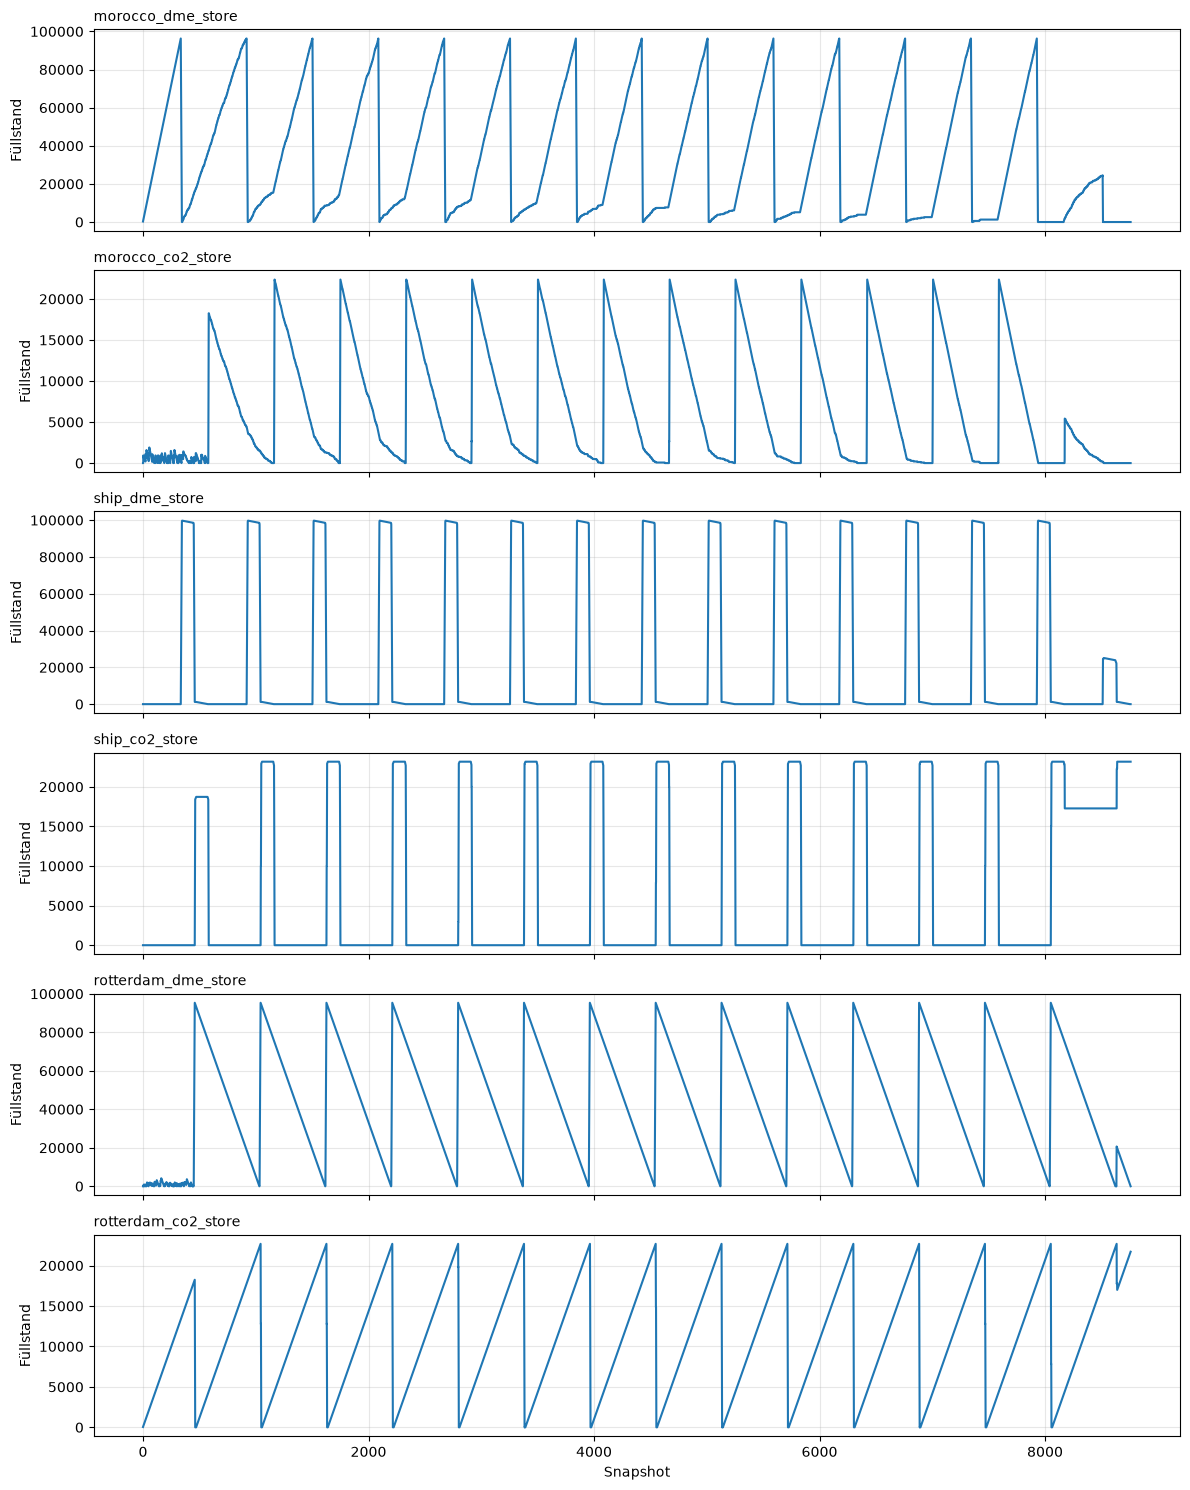

In [487]:
import matplotlib.pyplot as plt

stores = n.stores_t.e.copy()
fig, axes = plt.subplots(len(stores.columns), 1, figsize=(12, 2.5*len(stores.columns)), sharex=True)
for ax, col in zip(axes, stores.columns):
    ax.plot(stores.index, stores[col])
    ax.set_ylabel("Füllstand")
    ax.set_title(col, fontsize=10, loc="left")
    ax.grid(alpha=0.3)
axes[-1].set_xlabel("Snapshot")
plt.tight_layout()
plt.show()

In [ ]:
print("Zielfunktionswert:", n.objective)
print("\nOptimierte Speichergrößen (e_nom_opt):")
print(n.stores.e_nom_opt)
print("\nOptimierte Link-Leistungen (p_nom_opt):")
print(n.links.p_nom_opt)
print("\nFüllstand min/max je Store:")
print(n.stores_t.e.agg(["min", "max"]).T)
print("CO2 welches am Anfang eingekauft werden muss in t:")
print(n.generators_t.p["morocco_init_co2_source"].sum())
print("DME welches am Anfang eingekauft werden muss in MWh:")
print(n.generators_t.p["rotterdam_init_dme_source"].sum())

Zielfunktionswert: 405533538.7677748

Optimierte Speichergrößen (e_nom_opt):
name
morocco_dme_store       96294.252874
morocco_co2_store       22356.137931
ship_dme_store         107745.736434
ship_co2_store          23165.333333
rotterdam_dme_store     95333.333333
rotterdam_co2_store     22689.333333
Name: e_nom_opt, dtype: float64

Optimierte Link-Leistungen (p_nom_opt):
name
morocco_dme_loading_link        10700.000000
morocco_co2_deloading_link       5000.000000
dme_generator                     337.164751
rotterdam_dme_deloading_link    10700.000000
rotterdam_co2_loading_link       5000.000000
hydrogen_generator                166.666667
Name: p_nom_opt, dtype: float64

Füllstand min/max je Store:
                              min           max
name                                           
morocco_dme_store   -0.000000e+00  96294.252874
morocco_co2_store   -0.000000e+00  22356.137931
ship_dme_store      -5.820766e-11  99733.333333
ship_co2_store      -0.000000e+00  23165.333333